# Results: quantized, pruned autoencoder anomaly trigger

Reads the CSVs and plots written by the pipeline (see README for the run order). Every cell prints a note instead of failing if its input file is missing. Nothing here re-trains anything.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
ROOT = Path.cwd()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent
R = ROOT / "results"

def load(name, folder=R):
    p = folder / name
    if not p.exists():
        print("missing:", p.relative_to(ROOT))
        return None
    return pd.read_csv(p)

## 1. Data and the trivial detector
Trivial score = mean of x² of the standardized input, i.e. the reconstruction error of an all-zero output. Any autoencoder has to beat it.

In [2]:
meta_p, npz_p = ROOT / "data/processed/meta.json", ROOT / "data/processed/dataset.npz"
triv = None
if meta_p.exists() and npz_p.exists():
    from sklearn.metrics import roc_auc_score
    meta = json.loads(meta_p.read_text())
    print("class counts:", meta["class_counts"])
    print("QCD split sizes:", meta["split_sizes"])
    z = np.load(npz_p)
    neg = (z["X_test_qcd"] ** 2).mean(axis=1)
    pos = {k[len("X_anom_"):]: (z[k] ** 2).mean(axis=1) for k in z.files if k.startswith("X_anom_")}
    def _auc(p):
        return roc_auc_score(np.r_[np.zeros(len(neg)), np.ones(len(p))], np.r_[neg, p])
    triv = {k: _auc(v) for k, v in pos.items()}
    triv["pooled"] = _auc(np.concatenate(list(pos.values())))
    print("trivial detector AUC:", {k: round(v, 3) for k, v in triv.items()})
else:
    print("data/processed not found; run python -m src.prepare_dataset")

class counts: {'g': 167125, 'q': 161066, 'w': 167083, 'z': 166875, 't': 167851}
QCD split sizes: {'train': 229733, 'val': 49228, 'test_qcd': 49230}
trivial detector AUC: {'w': 0.614, 'z': 0.648, 't': 0.822, 'pooled': 0.695}


## 2. FP32 baselines
Single-seed results from Phase 2 (all five architectures tried), then the 5-seed spread of the three swept architectures.

In [3]:
b = load("fp32_baseline_all.csv")
if b is None:
    b = load("fp32_baseline.csv")
if b is not None:
    display(b.filter(regex="arch|n_params|epochs_run|best_val|^auc_").round(3))
runs = load("sweep_runs.csv")
if runs is not None:
    fp = runs.drop_duplicates(["arch", "seed"])
    cols = [c for c in fp.columns if c.startswith("auc_") and c.endswith("_fp32")]
    display(fp.groupby("arch", sort=False)[cols].agg(["mean", "std"]).round(3))

,arch,n_params,epochs_run,best_val_loss,auc_w,auc_z,auc_t,auc_pooled
0,16-8-4-2-4-8-16,378,146,0.121,0.515,0.558,0.664,0.579
1,16-4-2-4-16,170,126,0.155,0.577,0.573,0.622,0.591
2,16-3-16,115,54,0.117,0.628,0.606,0.766,0.667
3,16-8-4-3-4-8-16,387,200,0.051,0.721,0.711,0.691,0.707
4,16-4-4-4-16,188,35,0.058,0.644,0.643,0.635,0.641


auc_w_fp32        auc_z_fp32        auc_t_fp32        auc_pooled_fp32       
                      mean    std       mean    std       mean    std            mean    std
arch                                                                                        
16-8-4-3-4-8-16      0.683  0.030      0.687  0.028      0.690  0.004           0.687  0.018
16-4-4-4-16          0.643  0.002      0.643  0.002      0.634  0.002           0.640  0.001
16-3-16              0.624  0.002      0.602  0.002      0.766  0.000           0.665  0.002

## 3. Compression sweep
`collapse_rate`: share of seeds where the model output (almost) nothing. `degraded_rate`: share of seeds with r² below 0.9× the FP32 model's. Thresholds are in `configs/default.yaml` and were chosen after seeing results (see README).

In [4]:
tab = load("compression_table.csv")
if tab is not None:
    cols = ["arch", "bits", "sparsity", "n_seeds", "nnz_params", "total_weight_bits", "r2_mean",
            "collapse_rate", "degraded_rate", "auc_pooled_mean", "auc_pooled_std", "d_trivial_pooled_mean",
            "drop_pooled_mean", "drop_pooled_sem", "pareto", "pareto_full_quality"]
    display(tab.sort_values("total_weight_bits")[[c for c in cols if c in tab.columns]].round(3).reset_index(drop=True))

,arch,bits,sparsity,n_seeds,nnz_params,total_weight_bits,r2_mean,collapse_rate,degraded_rate,auc_pooled_mean,auc_pooled_std,d_trivial_pooled_mean,drop_pooled_mean,drop_pooled_sem,pareto,pareto_full_quality
0,16-3-16,4,0.75,5,22.2,88.8,0.566,0.0,1.0,0.639,0.042,-0.055,0.025,0.019,True,False
1,16-3-16,6,0.75,5,23.6,141.6,0.574,0.2,0.8,0.637,0.044,-0.057,0.027,0.020,False,False
2,16-3-16,4,0.50,5,41.4,165.6,0.756,0.0,1.0,0.674,0.016,-0.021,-0.009,0.007,True,False
3,16-3-16,8,0.75,5,26.4,211.2,0.568,0.2,0.8,0.606,0.084,-0.089,0.058,0.038,False,False
4,16-4-4-4-16,4,0.75,5,62.2,248.8,0.490,0.0,1.0,0.648,0.045,-0.047,-0.009,0.020,False,False
5,16-3-16,4,0.00,5,65.4,261.6,0.819,0.0,0.0,0.691,0.040,-0.004,-0.026,0.018,True,True
6,16-3-16,6,0.50,5,47.4,284.4,0.834,0.0,0.2,0.679,0.040,-0.016,-0.014,0.018,False,False
7,16-4-4-4-16,6,0.75,5,64.8,388.8,0.646,0.0,1.0,0.648,0.057,-0.047,-0.008,0.026,False,False
8,16-4-4-4-16,4,0.50,5,97.4,389.6,0.745,0.0,1.0,0.681,0.079,-0.014,-0.041,0.035,False,False
9,16-3-16,8,0.50,5,48.8,390.4,0.811,0.0,0.4,0.663,0.058,-0.032,0.002,0.026,False,False


### Pareto plot (weight bits vs pooled AUC)
x = FP32 reference, grey x = collapsed configs, hollow = degraded r², red dotted line = trivial detector. Bars are the std over seeds.

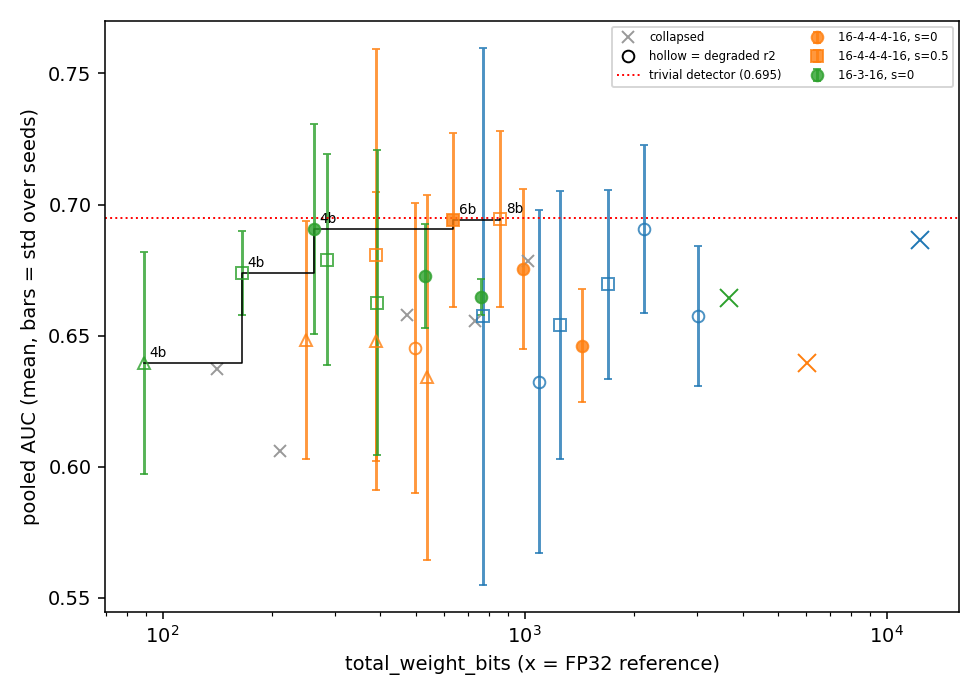

In [5]:
img = R / "pareto.png"
if img.exists():
    display(Image(filename=str(img)))
else:
    print("missing:", img.relative_to(ROOT))

### AUC against sparsity, per architecture and weight bit-width

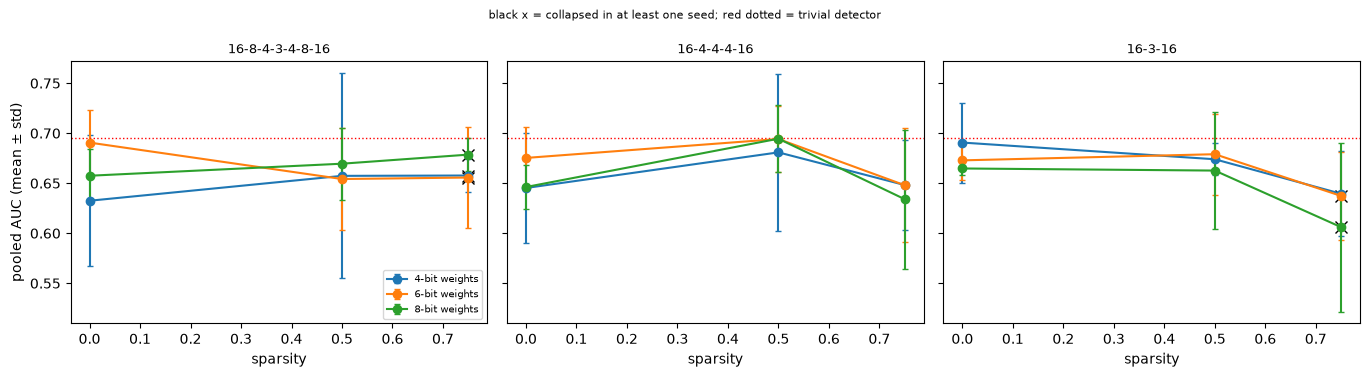

In [6]:
if tab is not None:
    archs = list(tab.arch.unique())
    fig, axes = plt.subplots(1, len(archs), figsize=(4.6 * len(archs), 3.8), sharey=True, squeeze=False)
    for ax, a in zip(axes[0], archs):
        for bits, g in tab[tab.arch == a].groupby("bits"):
            g = g.sort_values("sparsity")
            ax.errorbar(g.sparsity, g.auc_pooled_mean, yerr=g.auc_pooled_std.fillna(0), marker="o",
                        capsize=2, label=f"{bits}-bit weights")
            bad = g[g.collapse_rate > 0]
            ax.plot(bad.sparsity, bad.auc_pooled_mean, "kx", ms=9)
        if triv:
            ax.axhline(triv["pooled"], color="r", ls=":", lw=1)
        ax.set_title(a, fontsize=9)
        ax.set_xlabel("sparsity")
    axes[0][0].set_ylabel("pooled AUC (mean ± std)")
    axes[0][0].legend(fontsize=7)
    fig.suptitle("black x = collapsed in at least one seed; red dotted = trivial detector", fontsize=8)
    fig.tight_layout()
    plt.show()

### Reconstruction quality vs detection
The relation between reconstruction quality and AUC is only moderate and noisy: configs with similar r-squared can differ by several AUC points, so r-squared is reported next to AUC.

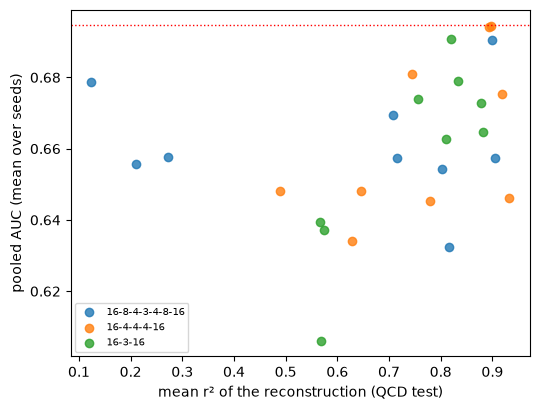

In [7]:
if tab is not None:
    fig, ax = plt.subplots(figsize=(5.5, 4.2))
    for i, (a, g) in enumerate(tab.groupby("arch", sort=False)):
        ax.scatter(g.r2_mean, g.auc_pooled_mean, color=f"C{i}", label=a, alpha=0.8)
    if triv:
        ax.axhline(triv["pooled"], color="r", ls=":", lw=1)
    ax.set_xlabel("mean r² of the reconstruction (QCD test)")
    ax.set_ylabel("pooled AUC (mean over seeds)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

### Per-class AUC minus the trivial detector (non-collapsed configs)
Positive = better than the trivial score. W and Z can improve while top jets stay worse.

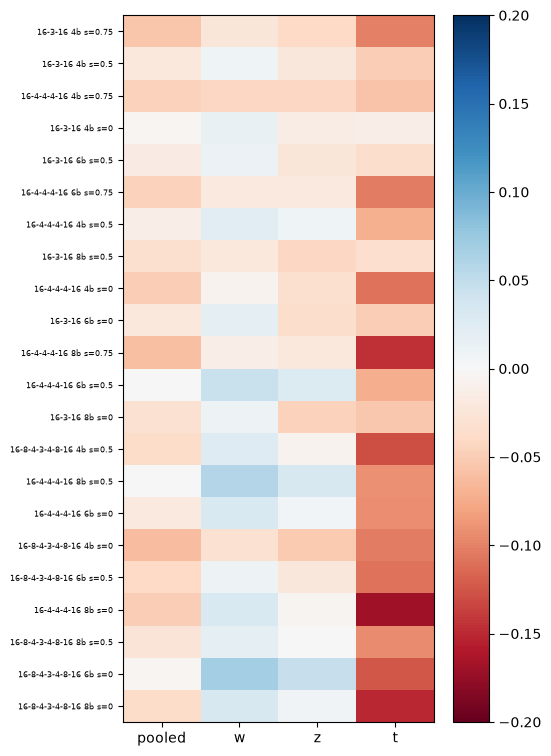

In [8]:
if tab is not None:
    v = tab[tab.collapse_rate == 0].sort_values("total_weight_bits")
    cc = [c for c in v.columns if c.startswith("d_trivial_") and c.endswith("_mean")]
    m = v[cc].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(5.5, 0.28 * len(v) + 1.5))
    im = ax.imshow(m, cmap="RdBu", vmin=-0.2, vmax=0.2, aspect="auto")
    ax.set_xticks(range(len(cc)))
    ax.set_xticklabels([c.replace("d_trivial_", "").replace("_mean", "") for c in cc])
    ax.set_yticks(range(len(v)))
    ax.set_yticklabels([f"{r.arch} {int(r.bits)}b s={r.sparsity:g}" for r in v.itertuples()], fontsize=6)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    plt.show()

## 4. Collapse check on the saved seed-42 models
`r2` near 0 or `pct_out_zero` near 100 means the model outputs nothing; `d_*` is the AUC minus the trivial detector's.

In [9]:
cc = load("collapse_check.csv")
if cc is not None:
    display(cc.round(3))

,arch,bits,sparsity,r2,pct_out_zero,auc_pooled,d_pooled,auc_w,d_w,auc_z,d_z,auc_t,d_t
0,16-8-4-3-4-8-16,32,0.00,0.949,0.000,0.707,0.013,0.721,0.107,0.711,0.063,0.691,-0.131
1,16-8-4-3-4-8-16,8,0.00,0.900,1.016,0.632,-0.063,0.650,0.036,0.641,-0.007,0.606,-0.216
2,16-8-4-3-4-8-16,8,0.50,0.470,7.140,0.723,0.029,0.645,0.031,0.696,0.048,0.828,0.006
3,16-8-4-3-4-8-16,8,0.75,-0.000,75.000,0.692,-0.003,0.611,-0.003,0.645,-0.003,0.819,-0.002
4,16-8-4-3-4-8-16,6,0.00,0.925,1.223,0.694,-0.000,0.690,0.076,0.692,0.044,0.702,-0.120
5,16-8-4-3-4-8-16,6,0.50,0.864,1.235,0.674,-0.021,0.635,0.022,0.626,-0.022,0.760,-0.062
6,16-8-4-3-4-8-16,6,0.75,0.355,37.607,0.682,-0.013,0.629,0.015,0.662,0.014,0.755,-0.067
7,16-8-4-3-4-8-16,4,0.00,0.849,1.840,0.591,-0.103,0.549,-0.065,0.562,-0.086,0.663,-0.158
8,16-8-4-3-4-8-16,4,0.50,0.718,1.614,0.764,0.069,0.747,0.133,0.763,0.115,0.781,-0.041
9,16-8-4-3-4-8-16,4,0.75,0.385,19.340,0.656,-0.039,0.652,0.038,0.674,0.026,0.642,-0.180


## 5. hls4ml agreement (C-simulation, seed-42 models)
`agrees` = at least 99% of outputs within one output LSB (1/32). AUC columns compare the Keras and hls4ml models on the same jets.

In [10]:
h = load("hls_agreement.csv")
if h is not None:
    print(f"{int(h.agrees.sum())} of {len(h)} configs agree within 1 LSB for 99% of outputs")
    print("max |AUC difference| between Keras and hls4ml:", round(h.auc_diff.abs().max(), 4))
    display(h[~h.agrees][["arch", "bits", "sparsity", "max_abs_diff", "p99_abs_diff", "frac_within_atol",
                          "auc_pooled_keras", "auc_pooled_hls4ml"]].round(4))

20 of 27 configs agree within 1 LSB for 99% of outputs
max |AUC difference| between Keras and hls4ml: 0.0003


,arch,bits,sparsity,max_abs_diff,p99_abs_diff,frac_within_atol,auc_pooled_keras,auc_pooled_hls4ml
0,16-8-4-3-4-8-16,8,0.0,0.2188,0.0625,0.9849,0.6333,0.6333
3,16-8-4-3-4-8-16,6,0.0,0.2500,0.0625,0.9857,0.6952,0.6950
6,16-8-4-3-4-8-16,4,0.0,0.2812,0.0625,0.9865,0.5916,0.5916
7,16-8-4-3-4-8-16,4,0.5,0.2500,0.0625,0.9897,0.7687,0.7688
9,16-4-4-4-16,8,0.0,0.2188,0.0625,0.9883,0.6366,0.6363
12,16-4-4-4-16,6,0.0,0.2812,0.0625,0.9884,0.6575,0.6575
15,16-4-4-4-16,4,0.0,0.2812,0.0625,0.9882,0.6093,0.6095


## 6. Resource proxies (mode C) and latency
Multiplier counts, weight bits and BOPs from the saved seed-42 models. **No LUT/DSP numbers and no cycle counts exist**; latency was not assessed.

In [11]:
rc = load("resource_estimates_C.csv")
if rc is not None:
    rc = rc.copy()
    rc["x_fewer_bits_than_fp32_baseline"] = (387 * 32) / rc.total_weight_bits
    display(rc[["arch", "bits", "sparsity", "n_mult", "total_weight_bits", "bops", "layer_depth",
                "x_fewer_bits_than_fp32_baseline"]].round(1))
lat = load("latency_report.csv")
if lat is not None:
    print("cycle estimates available:", int(lat.latency_best_cycles.notna().sum()), "of", len(lat))

,arch,bits,sparsity,n_mult,total_weight_bits,bops,layer_depth,x_fewer_bits_than_fp32_baseline
0,16-8-4-3-4-8-16,8,0.0,333,2992,27701.0,6,4.1
1,16-8-4-3-4-8-16,8,0.5,171,1696,14225.5,6,7.3
2,16-8-4-3-4-8-16,8,0.8,86,1016,7154.8,6,12.2
3,16-8-4-3-4-8-16,6,0.0,316,2142,20590.0,6,5.8
4,16-8-4-3-4-8-16,6,0.5,170,1254,11081.5,6,9.9
5,16-8-4-3-4-8-16,6,0.8,86,750,5606.8,6,16.5
6,16-8-4-3-4-8-16,4,0.0,237,1108,11146.0,6,11.2
7,16-8-4-3-4-8-16,4,0.5,158,780,7445.5,6,15.9
8,16-8-4-3-4-8-16,4,0.8,85,476,4010.8,6,26.0
9,16-4-4-4-16,8,0.0,158,1488,13080.0,4,8.3


cycle estimates available: 0 of 27


## 7. Summary numbers

In [12]:
if tab is not None:
    valid = tab[tab.collapse_rate == 0]
    print("configs:", len(tab), "| collapsed in >=1 seed:", int((tab.collapse_rate > 0).sum()),
          "| full quality:", int(tab.full_quality.sum()) if "full_quality" in tab else "n/a")
    if triv:
        print("non-collapsed configs beating the trivial detector (pooled):",
              int((valid.d_trivial_pooled_mean > 0).sum()), "of", len(valid))
    ok = valid[(valid.param_reduction_vs_baseline >= 0.6) & (valid.drop_pooled_mean < 0.02)]
    print("non-collapsed, >=60% fewer params and mean pooled drop < 0.02:", len(ok))
    print("Pareto points:", int(tab.pareto.sum()), "| full-quality only:", int(tab.pareto_full_quality.sum()))

configs: 27 | collapsed in >=1 seed: 5 | full quality: 6
non-collapsed configs beating the trivial detector (pooled): 0 of 22
non-collapsed, >=60% fewer params and mean pooled drop < 0.02: 13
Pareto points: 5 | full-quality only: 2
